# 02 · Retention & delivery: do late deliveries stop customers coming back?

**Questions**
1. How do monthly customer cohorts retain over time?
2. Are customers whose *first* order arrived late less likely to buy again?
3. Does the first review score predict a second purchase?

Data: `fct_orders` from `data/olist.duckdb` (built by `python src/build_db.py`).

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
con = duckdb.connect("../data/olist.duckdb", read_only=True)

## Defining a *real* repeat purchase

Two traps to avoid:
- **Same-day orders**: some customers split one basket into several orders on the same day. That's not loyalty, so a repeat must be on a **later day**.
- **Unequal observation time**: a customer who first bought in Aug 2018 had almost no time to return before the data ends. So we look at first orders **up to Feb 2018** and count a repeat only **within 180 days**.

In [2]:
customers = con.execute("""
WITH delivered AS (
    SELECT * FROM fct_orders
    WHERE order_status = 'delivered' AND delivered_at IS NOT NULL
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchased_at) AS rn
    FROM delivered
),
first_order AS (SELECT * FROM ranked WHERE rn = 1)
SELECT
    f.customer_unique_id,
    f.purchased_at                AS first_purchase,
    f.purchase_month              AS cohort,
    f.is_late, f.delay_days, f.review_score, f.order_value, f.customer_state,
    MAX(CASE WHEN CAST(d.purchased_at AS DATE) > CAST(f.purchased_at AS DATE)
              AND d.purchased_at <= f.purchased_at + INTERVAL 180 DAY
             THEN 1 ELSE 0 END)   AS repeat_180d
FROM first_order f
LEFT JOIN delivered d USING (customer_unique_id)
GROUP BY ALL
""").df()

base = customers[customers["first_purchase"] < "2018-03-01"].copy()
print(f"Customers in analysis window: {len(base):,}")
print(f"180-day repeat rate:          {base['repeat_180d'].mean():.2%}")

Customers in analysis window: 55,523
180-day repeat rate:          1.97%


## 1 · Cohort retention
Share of each monthly cohort that placed another order *n* months after their first one.

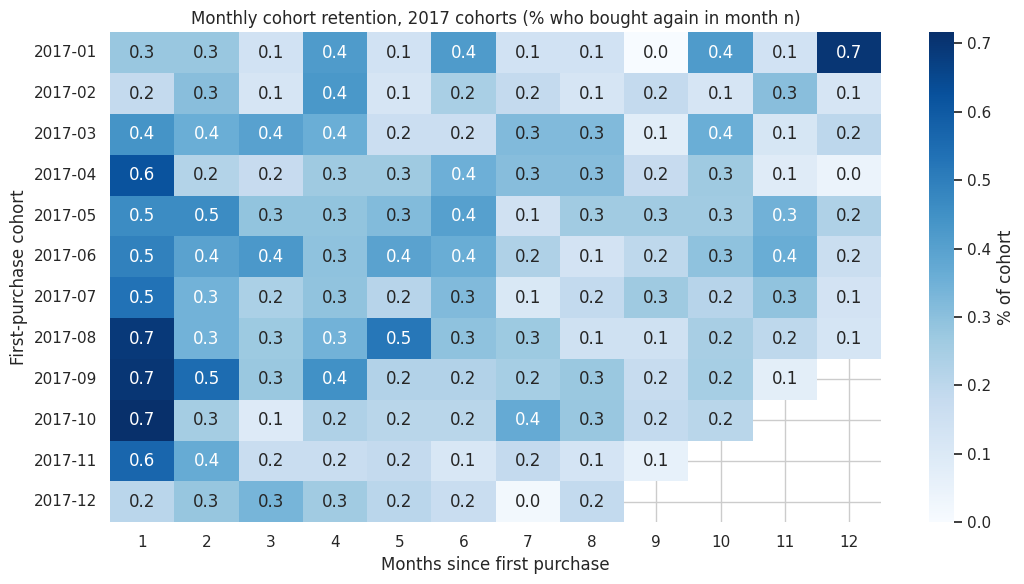

Average month-1 retention: 0.49%


In [3]:
orders = con.execute("""
SELECT customer_unique_id, purchase_month
FROM fct_orders
WHERE order_status = 'delivered'
""").df()

first = orders.groupby("customer_unique_id")["purchase_month"].min().rename("cohort")
orders = orders.join(first, on="customer_unique_id")
orders["month_n"] = ((orders["purchase_month"].dt.year - orders["cohort"].dt.year) * 12
                     + (orders["purchase_month"].dt.month - orders["cohort"].dt.month))

cohort_counts = (orders.groupby(["cohort", "month_n"])["customer_unique_id"]
                 .nunique().unstack(fill_value=0))
retention = cohort_counts.div(cohort_counts[0], axis=0) * 100
retention = retention.loc["2017-01-01":"2017-12-01", 1:12]

# Hide months after the data ends (they are unobserved, not 0%)
last_month = orders["purchase_month"].max()
for cohort in retention.index:
    for n in retention.columns:
        if cohort + pd.DateOffset(months=int(n)) > last_month:
            retention.loc[cohort, n] = float("nan")
retention.index = retention.index.strftime("%Y-%m")

plt.figure(figsize=(11, 6))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of cohort"})
plt.title("Monthly cohort retention, 2017 cohorts (% who bought again in month n)")
plt.xlabel("Months since first purchase"); plt.ylabel("First-purchase cohort")
plt.tight_layout(); plt.savefig(FIG + "cohort_retention.png", dpi=150); plt.show()

print(f"Average month-1 retention: {retention[1].mean():.2f}%")

## 2 · Late first delivery vs. coming back
Chi-square test: is the repeat rate independent of whether the first order was late?

         customers  repeat_rate_pct
is_late                            
on time      51256             2.00
late          4267             1.69

chi2 = 1.78, p = 0.1818
Late first delivery -> 15% lower relative repeat rate


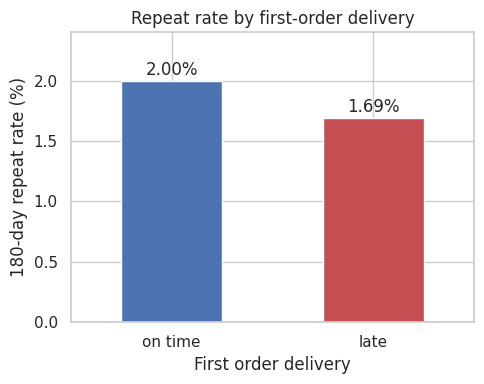

In [4]:
late_tbl = (base.groupby("is_late")["repeat_180d"]
            .agg(customers="count", repeat_rate="mean")
            .rename(index={0: "on time", 1: "late"}))
late_tbl["repeat_rate_pct"] = (late_tbl["repeat_rate"] * 100).round(2)
print(late_tbl[["customers", "repeat_rate_pct"]])

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(base["is_late"], base["repeat_180d"]))
rel = 1 - late_tbl.loc["late", "repeat_rate"] / late_tbl.loc["on time", "repeat_rate"]
print(f"\nchi2 = {chi2:.2f}, p = {p:.4f}")
print(f"Late first delivery -> {rel:.0%} lower relative repeat rate")

ax = late_tbl["repeat_rate_pct"].plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 4), rot=0)
ax.set_ylabel("180-day repeat rate (%)"); ax.set_xlabel("First order delivery")
ax.set_ylim(0, late_tbl["repeat_rate_pct"].max() * 1.2)
ax.set_title("Repeat rate by first-order delivery")
for i, v in enumerate(late_tbl["repeat_rate_pct"]): ax.text(i, v + 0.05, f"{v:.2f}%", ha="center")
plt.tight_layout(); plt.savefig(FIG + "repeat_by_late.png", dpi=150); plt.show()

## 3 · First review score vs. coming back

In [5]:
score_tbl = (base.dropna(subset=["review_score"])
             .groupby("review_score")["repeat_180d"]
             .agg(customers="count", repeat_rate="mean"))
score_tbl["repeat_rate_pct"] = (score_tbl["repeat_rate"] * 100).round(2)
print(score_tbl[["customers", "repeat_rate_pct"]])

late_reviews = (con.execute("""
SELECT is_late, AVG(review_score) AS avg_review,
       AVG(CASE WHEN review_score = 1 THEN 1 ELSE 0 END) * 100 AS one_star_pct
FROM fct_orders WHERE order_status = 'delivered' AND delivered_at IS NOT NULL
GROUP BY is_late ORDER BY is_late""").df())
print("\n", late_reviews.round(2))

              customers  repeat_rate_pct
review_score                            
1                  5486             1.73
2                  1768             1.53
3                  4810             1.93
4                 11074             1.82
5                 31973             2.11

    is_late  avg_review  one_star_pct
0        0        4.29          6.56
1        1        2.57         45.23


## Conclusions

1. **Retention is extremely low across every cohort.** Only ~0.5% of customers buy again in the month after their first purchase, and no 2017 cohort ever goes above ~0.7% in any later month. Olist behaves like a one-off marketplace, not a repeat-shopping store.
2. **Late delivery badly hurts satisfaction:** 2.57★ vs 4.29★ on average, and 45% of late orders get a 1-star review (vs 7% on time).
3. **But late delivery does not significantly reduce repeat purchases.** Customers whose first order was late came back at 1.69% vs 2.00% (15% lower in relative terms), but the difference is **not statistically significant** (χ² p ≈ 0.18). The first review score shows no clear pattern either.

**So what?** Fixing delivery would protect ratings and seller reputation, but it would not solve retention by itself. The low repeat rate is structural, so the next step is to find *which* customers and categories do return (RFM segmentation) and target them.